In [1]:
# Importing Libraries
import sqlite3
import pandas as pd
import plotly.express as px
import plotly.io as pio

In [2]:
# Import database
conn = sqlite3.connect("C:/Users/atd29/OneDrive/Documents/University/ECONOMIC MASTERS/ECON1205/econ1205_CW_database.db")

In [3]:
# Examine db structure
cursor = conn.cursor()
cursor.execute("SELECT name FROM sqlite_master WHERE type = 'table';")
print(cursor.fetchall())

[('carbon_gdp_intensity',), ('consumer_price_inflation',), ('gdp',), ('gdp_per_capita',), ('gdp_per_capita_growth',), ('net_energy_imports',), ('countries',)]


In [4]:
# Read in the tables
df_carbon = pd.read_sql_query("SELECT * FROM carbon_gdp_intensity", conn)
df_inflation = pd.read_sql_query("SELECT * FROM consumer_price_inflation", conn)
df_gdp = pd.read_sql_query("SELECT * FROM gdp", conn)
df_gdp_pc = pd.read_sql_query("SELECT * FROM gdp_per_capita", conn)
df_gdp_pcg = pd.read_sql_query("SELECT * FROM gdp_per_capita_growth", conn)
df_energy = pd.read_sql_query("SELECT * FROM net_energy_imports", conn)
df_countries = pd.read_sql_query("SELECT * FROM countries", conn)

In [5]:
# Rename columns
df_carbon = df_carbon.rename(columns={"2022 [YR2022]": "Carbon GDP Intensity"})
df_inflation = df_inflation.rename(columns={"2022 [YR2022]": "Consumer Price Inflation %"})
df_gdp = df_gdp.rename(columns={"2022 [YR2022]": "GDP US$"})
df_gdp_pc = df_gdp_pc.rename(columns={"2022 [YR2022]": "GDP Per Capita US$"})
df_gdp_pcg = df_gdp_pcg.rename(columns={"2022 [YR2022]": "GDP Per Capita Growth %"})
df_energy = df_energy.rename(columns={"2022 [YR2022]": "Net Energy Imports %"})

In [6]:
# Eyeball
df_countries.head()

,country_code,country_name
0,AFG,Afghanistan
1,ALB,Albania
2,DZA,Algeria
3,ASM,American Samoa
4,AND,Andorra


In [7]:
# Eyeball again
df_carbon.head()

,Country Code,Series Name,Series Code,Carbon GDP Intensity
0,AFG,Carbon intensity of GDP (kg CO2e per constant ...,EN.GHG.CO2.RT.GDP.KD,0.737216
1,ALB,Carbon intensity of GDP (kg CO2e per constant ...,EN.GHG.CO2.RT.GDP.KD,0.31448
2,DZA,Carbon intensity of GDP (kg CO2e per constant ...,EN.GHG.CO2.RT.GDP.KD,0.915412
3,ASM,Carbon intensity of GDP (kg CO2e per constant ...,EN.GHG.CO2.RT.GDP.KD,0.000151
4,AND,Carbon intensity of GDP (kg CO2e per constant ...,EN.GHG.CO2.RT.GDP.KD,..


In [8]:
# Merge 'carbon' and 'gdp' dataframes (1)
df101 = pd.merge(left = df_carbon,
                 right = df_gdp,
                 how = 'left',
                 left_on = ['Country Code'],
                 right_on = ['Country Code'],
                )

In [9]:
# Eyeball
df101.head()

,Country Code,Series Name_x,Series Code_x,Carbon GDP Intensity,Series Name_y,Series Code_y,GDP US$
0,AFG,Carbon intensity of GDP (kg CO2e per constant ...,EN.GHG.CO2.RT.GDP.KD,0.737216,GDP (current US$),NY.GDP.MKTP.CD,14497243872.133699
1,ALB,Carbon intensity of GDP (kg CO2e per constant ...,EN.GHG.CO2.RT.GDP.KD,0.31448,GDP (current US$),NY.GDP.MKTP.CD,19017247013.882099
2,DZA,Carbon intensity of GDP (kg CO2e per constant ...,EN.GHG.CO2.RT.GDP.KD,0.915412,GDP (current US$),NY.GDP.MKTP.CD,225581644702.567993
3,ASM,Carbon intensity of GDP (kg CO2e per constant ...,EN.GHG.CO2.RT.GDP.KD,0.000151,GDP (current US$),NY.GDP.MKTP.CD,871000000
4,AND,Carbon intensity of GDP (kg CO2e per constant ...,EN.GHG.CO2.RT.GDP.KD,..,GDP (current US$),NY.GDP.MKTP.CD,3380612573.4825


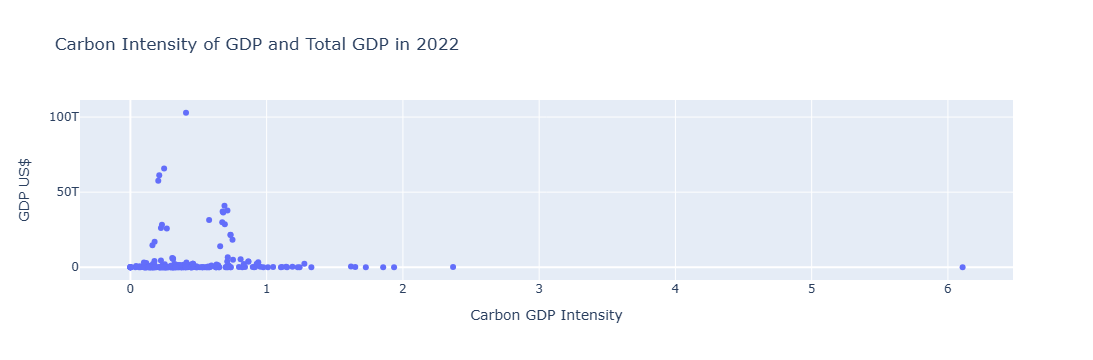

In [10]:
# Plot an interactive scatter diagram of all countries (1)
fig101 = px.scatter(df101,
                    x = "Carbon GDP Intensity",
                    y = "GDP US$",
                    hover_data = ["Country Code"],
                    title = "Carbon Intensity of GDP and Total GDP in 2022")
fig101.show()

# Interpretation of results (1)
Some outliers:
- Palau (PLW) far exceeds any other country's Carbon GDP Intensity. This is due to imported fossil fuels and small population (Ritchie & Rosado, 2025).
- WLD - World Aggregate
- HIC - High Income Countries
- OED - OECD Countries (38)
- PST - Post-demographic dividend economies (fertility rates below replacement levels)

Patterns:
- Ukraine (UKR), Venezuela (VEN), Turkmenistan (TKM), Iran (IRN) and Syria (SYR) have higher Carbon GDP Intensity. 2022 is notably the year that the Ukraine-Russia war started. The countries on the right of the graph are either currently in a state of war, or are located in the middle-east. 
- Switzerland (CHE) and some small nations (such as Bermuda) populate the furthest left of the graph. These are notably nations that are well known for pioneering climate-friendly economic practices (emitting less carbon & waste).
- The graph is stretched on the y-axis due to the aggregate datapoints (such as WLD, HIC). This hides countries like China (CHN), which has a high GDP and Carbon GDP Intensity for an individual country. 

In [11]:
# Merge GDP Per Capita Growth and Consumer Price Inflation (2)
df102 = pd.merge(left = df_gdp_pcg,
                 right = df_inflation,
                 how = 'left',
                 left_on = ['Country Code'],
                 right_on = ['Country Code'],
                )
df102.head()

,Country Code,Series Name_x,Series Code_x,GDP Per Capita Growth %,Series Name_y,Series Code_y,Consumer Price Inflation %
0,AFG,GDP per capita growth (annual %),NY.GDP.PCAP.KD.ZG,-7.576669,"Inflation, consumer prices (annual %)",FP.CPI.TOTL.ZG,13.712102
1,ALB,GDP per capita growth (annual %),NY.GDP.PCAP.KD.ZG,6.456988,"Inflation, consumer prices (annual %)",FP.CPI.TOTL.ZG,6.725203
2,DZA,GDP per capita growth (annual %),NY.GDP.PCAP.KD.ZG,1.968252,"Inflation, consumer prices (annual %)",FP.CPI.TOTL.ZG,9.265516
3,ASM,GDP per capita growth (annual %),NY.GDP.PCAP.KD.ZG,3.593276,"Inflation, consumer prices (annual %)",FP.CPI.TOTL.ZG,..
4,AND,GDP per capita growth (annual %),NY.GDP.PCAP.KD.ZG,7.721238,"Inflation, consumer prices (annual %)",FP.CPI.TOTL.ZG,..


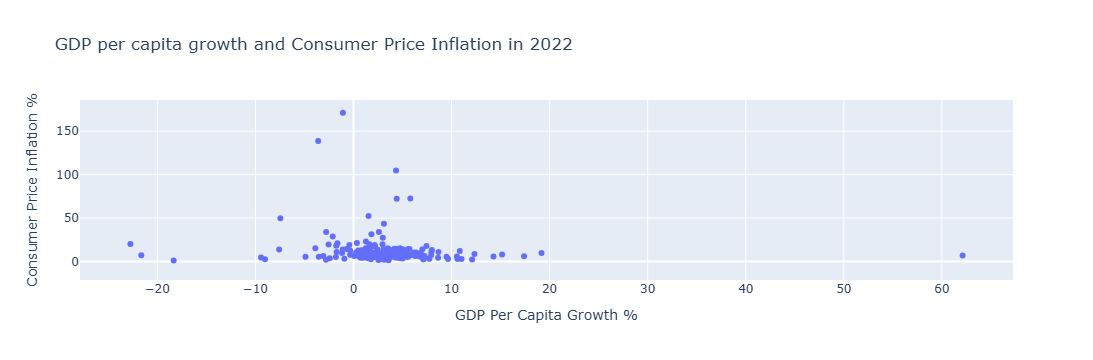

In [12]:
# Plot (2)
fig102 = px.scatter(df102,
                    x = "GDP Per Capita Growth %", 
                    y = "Consumer Price Inflation %",
                    hover_data = ["Country Code"],
                    title = "GDP per capita growth and Consumer Price Inflation in 2022")
fig102.show()

# Interpretation of results (2)

### World Averages
#### Consumer Price Inflation: 8.00%
#### GDP Per Capita Growth: 2.55%

Outliers:
- Guyana (GUY), Fiji (FJI) and Saint Lucia (LCA) are the countries with the highest GDP Per Capita Growth, with Guyana being well over 60% annual growth.
- Lebanon (LBN), Sudan (SDN) and Zimbabwe (ZWE) have the highest consumer price inflation ~ topping out at over 150% annually in Lebanon.
- The countries with the lowest GDP Per Capita Growth are: Ukraine (UKR), Timor-Leste (TLS), and Macau (MAC).

Patterns:
- Datapoints found in the graph furthest from the world averages tend to be developing economies or nations in a state of war (Ukraine, etc.).

In [13]:
# Merge carbon and energy (3)
df103 = pd.merge(left = df_carbon,
                 right = df_energy,
                 how = 'left',
                 left_on = ['Country Code'],
                 right_on = ['Country Code'],
                )
df103.head()

,Country Code,Series Name_x,Series Code_x,Carbon GDP Intensity,Series Name_y,Series Code_y,Net Energy Imports %
0,AFG,Carbon intensity of GDP (kg CO2e per constant ...,EN.GHG.CO2.RT.GDP.KD,0.737216,"Energy imports, net (% of energy use)",EG.IMP.CONS.ZS,..
1,ALB,Carbon intensity of GDP (kg CO2e per constant ...,EN.GHG.CO2.RT.GDP.KD,0.31448,"Energy imports, net (% of energy use)",EG.IMP.CONS.ZS,32.276397
2,DZA,Carbon intensity of GDP (kg CO2e per constant ...,EN.GHG.CO2.RT.GDP.KD,0.915412,"Energy imports, net (% of energy use)",EG.IMP.CONS.ZS,-127.189852
3,ASM,Carbon intensity of GDP (kg CO2e per constant ...,EN.GHG.CO2.RT.GDP.KD,0.000151,"Energy imports, net (% of energy use)",EG.IMP.CONS.ZS,..
4,AND,Carbon intensity of GDP (kg CO2e per constant ...,EN.GHG.CO2.RT.GDP.KD,..,"Energy imports, net (% of energy use)",EG.IMP.CONS.ZS,..


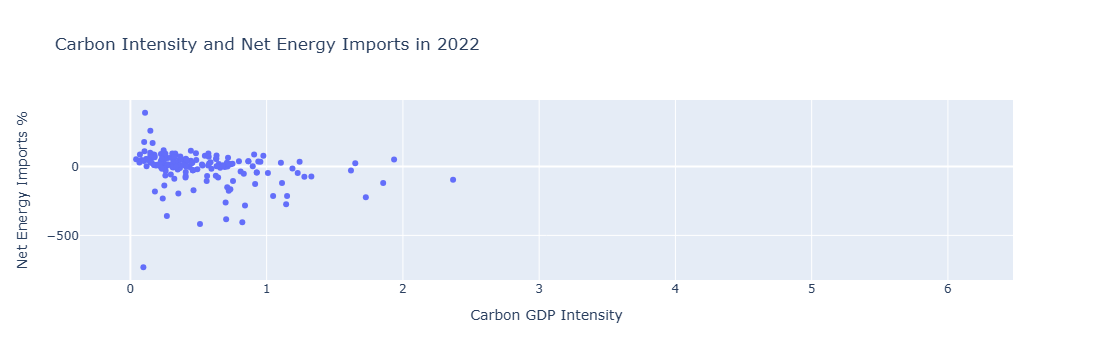

In [14]:
# Plot (3)
fig103 = px.scatter(df103,
                    x = "Carbon GDP Intensity", 
                    y = "Net Energy Imports %",
                    hover_data = ["Country Code"],
                    title = "Carbon Intensity and Net Energy Imports in 2022")
fig103.show()

# Interpretation of results (3)
Outliers:
- Norway (NOR), Malta (MLT), Singapore (SGP), Hong Kong (HKG), and Panama (PAN).
- Countries with a positive NEI% import more energy than they export, and tend to have lower Carbon GDP Intensity possibly due to them not making all of their power locally. Notable exceptions are Ukraine and Syria, as they both import more but also produce more carbon emissions per capita.

Patterns:
- Datapoints below x=0 (countries with net energy exports > imports) are more spread out. This could be a reflection on how diverse energy sources can be and how different countries implement different energy generation strategies (some countries may rely heavily on local coal power, whereas another may focus on hydropower for example).

In [15]:
# Merge GDP per capita growth and GDP per capita (4)
df104 = pd.merge(left = df_gdp_pcg,
                 right = df_gdp_pc,
                 how = 'left',
                 left_on = ['Country Code'],
                 right_on = ['Country Code'],
                )
df104.head()

,Country Code,Series Name_x,Series Code_x,GDP Per Capita Growth %,Series Name_y,Series Code_y,GDP Per Capita US$
0,AFG,GDP per capita growth (annual %),NY.GDP.PCAP.KD.ZG,-7.576669,GDP per capita (current US$),NY.GDP.PCAP.CD,357.261153
1,ALB,GDP per capita growth (annual %),NY.GDP.PCAP.KD.ZG,6.456988,GDP per capita (current US$),NY.GDP.PCAP.CD,7756.961887
2,DZA,GDP per capita growth (annual %),NY.GDP.PCAP.KD.ZG,1.968252,GDP per capita (current US$),NY.GDP.PCAP.CD,4960.303343
3,ASM,GDP per capita growth (annual %),NY.GDP.PCAP.KD.ZG,3.593276,GDP per capita (current US$),NY.GDP.PCAP.CD,18017.458938
4,AND,GDP per capita growth (annual %),NY.GDP.PCAP.KD.ZG,7.721238,GDP per capita (current US$),NY.GDP.PCAP.CD,42414.059011


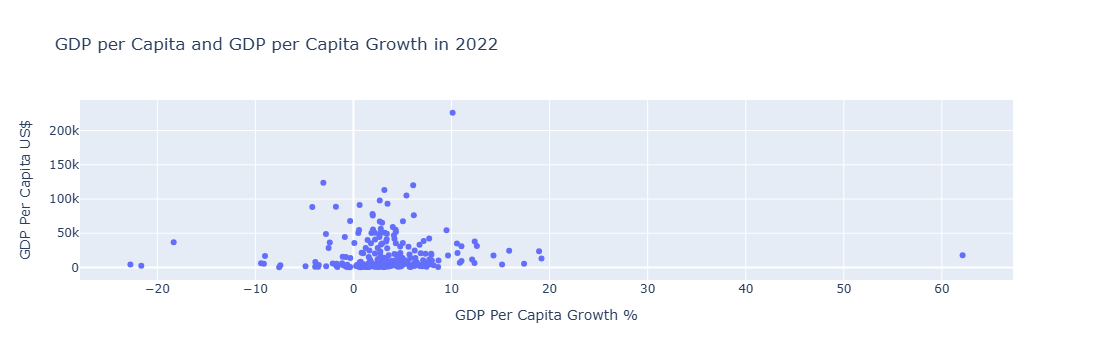

In [17]:
# Plot (4)
fig104 = px.scatter(df104,
                    x = "GDP Per Capita Growth %", 
                    y = "GDP Per Capita US$",
                    hover_data = ["Country Code"],
                    title = "GDP per Capita and GDP per Capita Growth in 2022")
fig104.show()

# Interpretation of results (4)
Outliers:
- Monaco (MCO) ~ Very low population but high GDP & GDP growth. A famous tax haven. 
- Ukraine (UKR), Timor-Leste (TLS), and Macau (MAC) ~ as mentioned in Interpretation of results (1)
- Guyana (GUY) ~ High GDP growth tied to increased oil output. High percentage change perhaps due to it being a smaller nation with a comparatively smaller GDP in year prior.

In [18]:
# Merge energy and inflation (5)
df105 = pd.merge(left = df_energy,
                 right = df_inflation,
                 how = 'left',
                 left_on = ['Country Code'],
                 right_on = ['Country Code'],
                )
df105.head()

,Country Code,Series Name_x,Series Code_x,Net Energy Imports %,Series Name_y,Series Code_y,Consumer Price Inflation %
0,AFG,"Energy imports, net (% of energy use)",EG.IMP.CONS.ZS,..,"Inflation, consumer prices (annual %)",FP.CPI.TOTL.ZG,13.712102
1,ALB,"Energy imports, net (% of energy use)",EG.IMP.CONS.ZS,32.276397,"Inflation, consumer prices (annual %)",FP.CPI.TOTL.ZG,6.725203
2,DZA,"Energy imports, net (% of energy use)",EG.IMP.CONS.ZS,-127.189852,"Inflation, consumer prices (annual %)",FP.CPI.TOTL.ZG,9.265516
3,ASM,"Energy imports, net (% of energy use)",EG.IMP.CONS.ZS,..,"Inflation, consumer prices (annual %)",FP.CPI.TOTL.ZG,..
4,AND,"Energy imports, net (% of energy use)",EG.IMP.CONS.ZS,..,"Inflation, consumer prices (annual %)",FP.CPI.TOTL.ZG,..


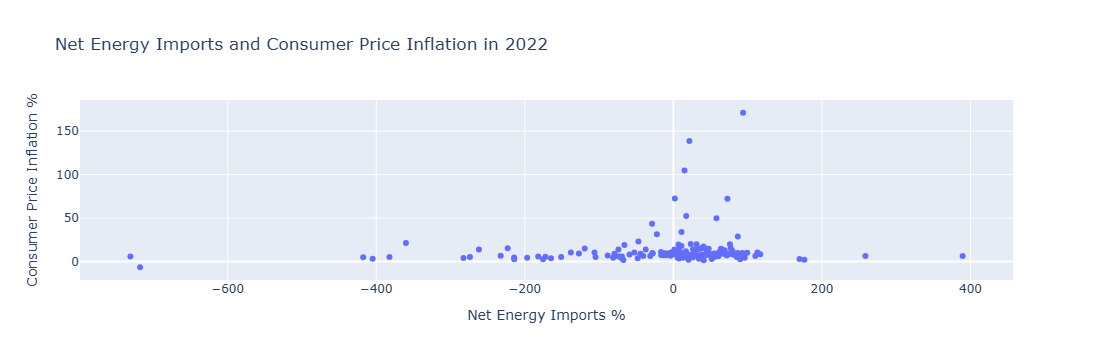

In [19]:
# Plot (5)
fig105 = px.scatter(df105,
                    x = "Net Energy Imports %", 
                    y = "Consumer Price Inflation %",
                    hover_data = ["Country Code"],
                    title = "Net Energy Imports and Consumer Price Inflation in 2022")
fig105.show()

### Interpretation of results (5)
Outliers:
- Norway (NOR) and the Republic of South Sudan (SSD) have very high energy exports. Note: South Sudan was not in the graph for Interpretation (3) due to incomplete data.

Patterns:
- Datapoints with higher consumer price inflation seem to be concentrated on the side of x>0. This could mean that countries that export energy have better control over consumer price inflation.
- Few reported cases of consumer price deflation. Any cases of deflation are close to 0% inflation, whereas cases of inflation are far more varied (up to 171% with Lebanon).

In [20]:
# Merge carbon and GDP per capita growth (6)
df106 = pd.merge(left = df_carbon,
                 right = df_gdp_pcg,
                 how = 'left',
                 left_on = ['Country Code'],
                 right_on = ['Country Code'],
                )
df106.head()

,Country Code,Series Name_x,Series Code_x,Carbon GDP Intensity,Series Name_y,Series Code_y,GDP Per Capita Growth %
0,AFG,Carbon intensity of GDP (kg CO2e per constant ...,EN.GHG.CO2.RT.GDP.KD,0.737216,GDP per capita growth (annual %),NY.GDP.PCAP.KD.ZG,-7.576669
1,ALB,Carbon intensity of GDP (kg CO2e per constant ...,EN.GHG.CO2.RT.GDP.KD,0.31448,GDP per capita growth (annual %),NY.GDP.PCAP.KD.ZG,6.456988
2,DZA,Carbon intensity of GDP (kg CO2e per constant ...,EN.GHG.CO2.RT.GDP.KD,0.915412,GDP per capita growth (annual %),NY.GDP.PCAP.KD.ZG,1.968252
3,ASM,Carbon intensity of GDP (kg CO2e per constant ...,EN.GHG.CO2.RT.GDP.KD,0.000151,GDP per capita growth (annual %),NY.GDP.PCAP.KD.ZG,3.593276
4,AND,Carbon intensity of GDP (kg CO2e per constant ...,EN.GHG.CO2.RT.GDP.KD,..,GDP per capita growth (annual %),NY.GDP.PCAP.KD.ZG,7.721238


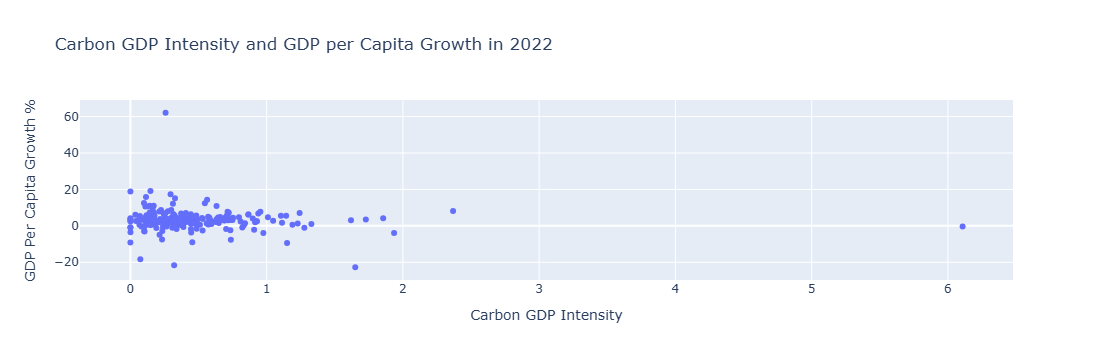

In [21]:
# Plot (6)
fig106 = px.scatter(df106,
                    x = "Carbon GDP Intensity", 
                    y = "GDP Per Capita Growth %",
                    hover_data = ["Country Code"],
                    title = "Carbon GDP Intensity and GDP per Capita Growth in 2022")
fig106.show()

### Interpretation of results (6)
- Similar distribution to plot 2.
- Appears that datapoints do not commonly share an extreme of both variables, rather one or the other.
- Weak correlation
- Not much to say for this plot that hasn't been said already with the others.


References

Hannah Ritchie and Pablo Rosado (2025) - “CO₂ and Greenhouse Gas Emissions” Published online at OurWorldinData.org. 
Retrieved from: 'https://ourworldindata.org/profile/co2/palau' [Online Resource]